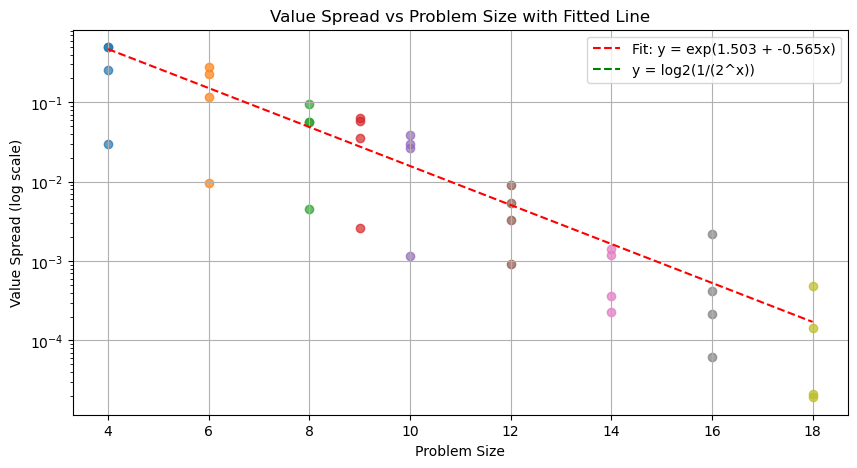

Fitted function: y = exp(1.503 + -0.565x)


In [ ]:
# naive approach (quadratic terms scaling, n qubits)
spread_data1 = {'4': [0.49468749999999984, 0.25875000000000004, 0.03, 0.49093749999999997], 
               '6': [0.282734375, 0.11656249999999999, 0.009609375, 0.22914062500000001], 
               '8': [0.09500000000000001, 0.0571484375, 0.00458984375, 0.05734374999999999], 
               '9': [0.06341796875000001, 0.035117187499999994, 0.0026269531250000004, 0.05901367187500001], 
               '10': [0.030083007812499996, 0.03873046875000001, 0.0011523437500000002, 0.026557617187500004], 
               '12': [0.005345458984375, 0.0090869140625, 0.0009179687500000001, 0.003291015625], 
               '14': [0.00118804931640625, 0.00141357421875, 0.00022857666015624993, 0.00036132812500000005], 
               '16': [0.00042015075683593745, 0.002164154052734375, 6.248474121093751e-05, 0.00021507263183593748], 
               '18': [0.00014261245727539064, 0.0004805946350097657, 2.1190643310546877e-05, 1.9283294677734377e-05]} 

sizes_spread = np.array(list(spread_data1.keys()), dtype=float)
means1 = np.array([np.mean(values) for values in spread_data1.values()])

# Plot spread with log scale and fitted line
plt.figure(figsize=(10, 5))
for size, values in spread_data1.items():
    plt.scatter([float(size)] * len(values), values, alpha=0.7)

# Fit a line in log-space
log_fit1 = np.polyfit(sizes_spread, np.log(means1), 1)
fit_values1 = np.exp(log_fit1[1] + log_fit1[0] * sizes_spread)
plt.plot(sizes_spread, fit_values1, linestyle='dashed', color='red', label=f"Fit: y = exp({log_fit1[1]:.3f} + {log_fit1[0]:.3f}x)")

plt.plot(sizes_spread, [np.log2(1/(2**x)) for x in sizes_spread], linestyle='dashed', color='green', label="y = log2(1/(2^x))")

plt.xlabel("Problem Size")
plt.ylabel("Value Spread (log scale)")
plt.title("Value Spread vs Problem Size with Fitted Line")
plt.yscale("log")
plt.legend()
plt.grid()
plt.show()

print(f"Fitted function: y = exp({log_fit1[1]:.3f} + {log_fit1[0]:.3f}x)")


c:\Users\Alexander's Laptop\Documents\Computing Stuff\Quantum\.conda\Lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\Alexander's Laptop\Documents\Computing Stuff\Quantum\.conda\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


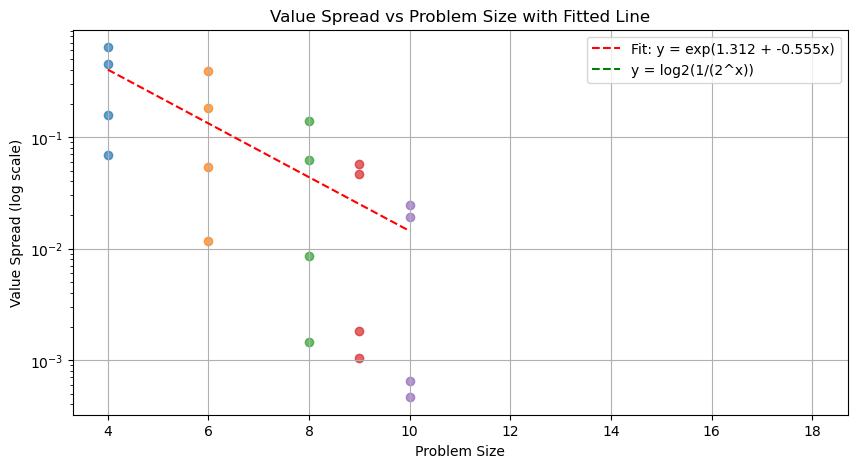

Fitted function: y = exp(1.312 + -0.555x)


In [6]:
# naive 2 approach (quadratic term scaling, 2n qubits)

import matplotlib.pyplot as plt
import numpy as np

spread_data2 = {'4': [0.4557812500000001, 0.6397460937499999, 0.06886718750000001, 0.15687500000000001], 
               '6': [0.182379150390625, 0.38808105468750004, 0.011654052734375, 0.053950195312500004], 
               '8': [0.06270378112792968, 0.13973899841308593, 0.0014451599121093751, 0.008656082153320314], 
               '9': [0.04700906753540039, 0.05730773925781252, 0.00104095458984375, 0.0018253326416015625], 
               '10': [0.0193494176864624, 0.024411211013793947, 0.0004645538330078125, 0.0006472015380859376],
               '12': [], '14': [], '16': [], '18': []}  

sizes_spread = np.array(list(spread_data2.keys()), dtype=float)
means2 = np.array([np.mean(values) for values in spread_data2.values()])

# Plot spread with log scale and fitted line
plt.figure(figsize=(10, 5))
for size, values in spread_data2.items():
    plt.scatter([float(size)] * len(values), values, alpha=0.7)

# Filter out nan values
valid_indices = ~np.isnan(means2)
filtered_sizes_spread = sizes_spread[valid_indices]
filtered_means2 = means2[valid_indices]

# Fit a line in log-space
log_fit2 = np.polyfit(filtered_sizes_spread, np.log(filtered_means2), 1)
fit_values2 = np.exp(log_fit2[1] + log_fit2[0] * filtered_sizes_spread)
plt.plot(filtered_sizes_spread, fit_values2, linestyle='dashed', color='red', label=f"Fit: y = exp({log_fit2[1]:.3f} + {log_fit2[0]:.3f}x)")

plt.plot(sizes_spread, [np.log2(1/(2**x)) for x in sizes_spread], linestyle='dashed', color='green', label="y = log2(1/(2^x))")

plt.xlabel("Problem Size")
plt.ylabel("Value Spread (log scale)")
plt.title("Value Spread vs Problem Size with Fitted Line")
plt.yscale("log")
plt.legend()
plt.grid()
plt.show()

print(f"Fitted function: y = exp({log_fit2[1]:.3f} + {log_fit2[0]:.3f}x)")

c:\Users\Alexander's Laptop\Documents\Computing Stuff\Quantum\.conda\Lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\Alexander's Laptop\Documents\Computing Stuff\Quantum\.conda\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


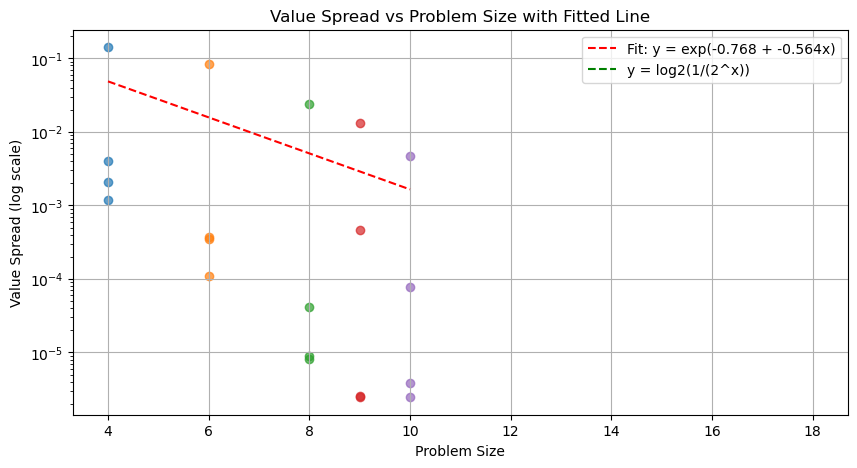

Fitted function: y = exp(-0.768 + -0.564x)


In [7]:
# quadratic non-naive approach (linear quadratic terms, 2n qubits)

import matplotlib.pyplot as plt
import numpy as np

spread_data3 = {'4': [0.14173828125000001, 0.00404296875, 0.00119140625, 0.00205078125], 
               '6': [0.08266235351562501, 0.00034667968749999993, 0.00010864257812499999, 0.000369873046875], 
               '8': [0.023729934692382812, 8.163452148437499e-06, 9.002685546875e-06, 4.18853759765625e-05], 
               '9': [0.013235816955566401, 2.5177001953124997e-06, 2.460479736328125e-06, 0.0004653358459472655], 
               '10': [0.004641418457031249, 2.5081634521484382e-06, 3.862380981445312e-06, 7.843971252441408e-05], '12': [], '14': [], '16': [], '18': []} 

sizes_spread = np.array(list(spread_data3.keys()), dtype=float)
means3 = np.array([np.mean(values) for values in spread_data3.values()])

# Plot spread with log scale and fitted line
plt.figure(figsize=(10, 5))
for size, values in spread_data3.items():
    plt.scatter([float(size)] * len(values), values, alpha=0.7)

# Filter out nan values
valid_indices = ~np.isnan(means3)
filtered_sizes_spread = sizes_spread[valid_indices]
filtered_means3 = means3[valid_indices]

# Fit a line in log-space
log_fit3 = np.polyfit(filtered_sizes_spread, np.log(filtered_means3), 1)
fit_values3 = np.exp(log_fit3[1] + log_fit3[0] * filtered_sizes_spread)
plt.plot(filtered_sizes_spread, fit_values3, linestyle='dashed', color='red', label=f"Fit: y = exp({log_fit3[1]:.3f} + {log_fit3[0]:.3f}x)")

plt.plot(sizes_spread, [np.log2(1/(2**x)) for x in sizes_spread], linestyle='dashed', color='green', label="y = log2(1/(2^x))")

plt.xlabel("Problem Size")
plt.ylabel("Value Spread (log scale)")
plt.title("Value Spread vs Problem Size with Fitted Line")
plt.yscale("log")
plt.legend()
plt.grid()
plt.show()

print(f"Fitted function: y = exp({log_fit3[1]:.3f} + {log_fit3[0]:.3f}x)")

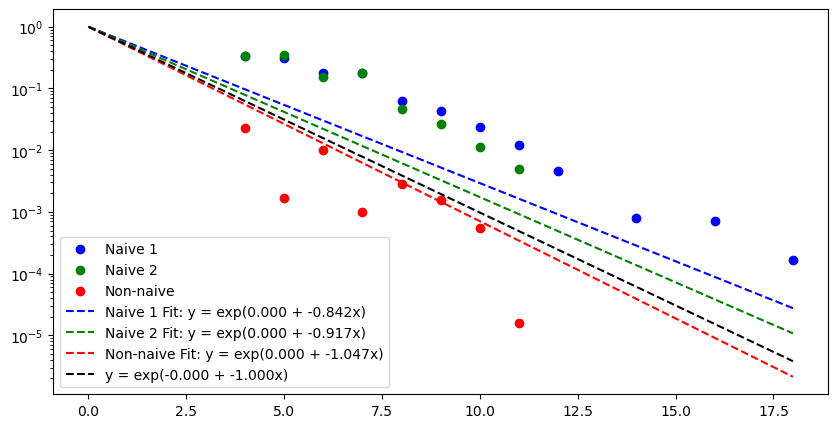

In [23]:
import numpy as np
import matplotlib.pyplot as plt


# naive approach (quadratic terms scaling, n qubits)
spread_data1 = {'4': [0.49468749999999984, 0.25875000000000004, 0.03, 0.49093749999999997, 0.495625, 0.33062499999999995, 0.480625, 0.1746875, 0.25999999999999995],
                '5': [0.465625, 0.3165625, 0.45828125000000003, 0.1234375, 0.20531249999999995], 
               '6': [0.282734375, 0.11656249999999999, 0.009609375, 0.22914062500000001, 0.32484375, 0.1525, 0.29976562500000004, 0.094296875, 0.10273437500000002], 
               '7': [0.29484375000000007, 0.13871093750000002, 0.28792968750000003, 0.06980468749999999, 0.08789062500000001],
               '8': [0.09500000000000001, 0.0571484375, 0.00458984375, 0.05734374999999999, 0.12658203125, 0.041718750000000006, 0.11900390624999999, 0.02927734375, 0.0403125], 
               '9': [0.06341796875000001, 0.035117187499999994, 0.0026269531250000004, 0.05901367187500001, 0.08154296874999999, 0.028955078124999995, 0.0754296875, 0.011396484374999998, 0.033720703124999994], 
               '10': [0.030083007812499996, 0.03873046875000001, 0.0011523437500000002, 0.026557617187500004, 0.022670898437499996, 0.010478515624999999, 0.03904296875, 0.0058203125, 0.039277343750000006], 
               '12': [0.005345458984375, 0.0090869140625, 0.0009179687500000001, 0.003291015625], 
               '11': [0.01325439453125, 0.0043115234375, 0.018369140625000002, 0.0036376953125, 0.021540527343749998],
               '14': [0.00118804931640625, 0.00141357421875, 0.00022857666015624993, 0.00036132812500000005], 
               '16': [0.00042015075683593745, 0.002164154052734375, 6.248474121093751e-05, 0.00021507263183593748], 
               '18': [0.00014261245727539064, 0.0004805946350097657, 2.1190643310546877e-05, 1.9283294677734377e-05]} 

sizes_spread = np.array(list(spread_data1.keys()), dtype=float)
means1 = np.array([np.mean(values) for values in spread_data1.values()])
valid_indices = ~np.isnan(means1)
sizes_spread1 = sizes_spread[valid_indices]
means1 = means1[valid_indices]
log_fit1 = np.polyfit(sizes_spread1, np.log2(means1), 1)  # Fit a line in log-space
log_fit1[1] = 0  # Force the line to pass through the origin

# naive 2n qubits
spread_data2 = {'4': [0.4557812500000001, 0.6397460937499999, 0.06886718750000001, 0.15687500000000001, 0.05732421875, 0.30755859375000005, 0.44830078125000006, 0.2873046875, 0.6439257812500001],
                '5': [0.027509765624999998, 0.3344775390625, 0.4272705078125001, 0.33791015625, 0.6387792968749999], 
               '6': [0.182379150390625, 0.38808105468750004, 0.011654052734375, 0.053950195312500004, 0.012374267578125, 0.1470947265625, 0.183004150390625, 0.13720336914062498, 0.27111083984375],
               '7': [0.0043072509765625005, 0.18002044677734377, 0.20385803222656249, 0.18212463378906246, 0.334759521484375], 
               '8': [0.06270378112792968, 0.13973899841308593, 0.0014451599121093751, 0.008656082153320314, 0.0016011047363281249, 0.03317184448242187, 0.049694976806640624, 0.0195953369140625, 0.09771636962890626], 
               '9': [0.04700906753540039, 0.05730773925781252, 0.00104095458984375, 0.0018253326416015625, 0.0006782150268554688, 0.01320377349853516, 0.0535130500793457, 0.018841915130615235, 0.04792232513427735], 
               '10': [0.0193494176864624, 0.024411211013793947, 0.0004645538330078125, 0.0006472015380859376, 0.00016175746917724608, 0.017746763229370115, 0.02673335552215576, 0.004974617958068848, 0.008454766273498535],
               '11': [5.2089691162109366e-05, 0.007343196868896484, 0.007775832414627075, 0.0031918656826019284, 0.006362107992172242],
               '12': [], '14': [], '16': [], '18': []}  

sizes_spread = np.array(list(spread_data2.keys()), dtype=float)
means2 = np.array([np.mean(values) for values in spread_data2.values()])
valid_indices = ~np.isnan(means2)
sizes_spread2 = sizes_spread[valid_indices]
means2 = means2[valid_indices]
log_fit2 = np.polyfit(sizes_spread2, np.log2(means2), 1)  # Fit a line in log-space
log_fit2[1] = 0  # Force the line to pass through the origin

# non-naive 2n qubits
spread_data3 = {'4': [0.14173828125000001, 0.00404296875, 0.00119140625, 0.00205078125, 0.0275390625, 0.00173828125, 0.0016601562500000004, 0.0013281249999999999, 0.02291015625],
                '5': [0.0022998046875, 0.0003759765625, 0.000390625, 0.00032226562499999996, 0.0048828125],
               '6': [0.08266235351562501, 0.00034667968749999993, 0.00010864257812499999, 0.000369873046875, 0.004222412109375, 0.0001220703125, 0.00037841796875, 0.00010620117187499999, 0.0031579589843750006], 
               '7': [0.0033233642578125, 2.960205078125e-05, 0.00057098388671875, 2.1667480468750002e-05, 0.00109619140625],
               '8': [0.023729934692382812, 8.163452148437499e-06, 9.002685546875e-06, 4.18853759765625e-05, 0.0009940338134765627, 7.705688476562502e-06, 0.00014549255371093748, 6.866455078125e-06, 0.0001265716552734375], 
               '9': [0.013235816955566401, 2.5177001953124997e-06, 2.460479736328125e-06, 0.0004653358459472655, 0.00025756835937500004, 5.168914794921875e-06, 9.84001159667969e-05, 1.697540283203125e-06, 0.00014705657958984374], 
               '10': [0.004641418457031249, 2.5081634521484382e-06, 3.862380981445312e-06, 7.843971252441408e-05, 8.996009826660156e-05, 1.888275146484375e-06, 9.375572204589843e-05, 4.57763671875e-07, 1.2679100036621092e-05],
               '11': [6.043672561645508e-05, 2.0980834960937497e-07, 2.8800964355468754e-06, 1.1086463928222657e-07],
               '12': [], '14': [], '16': [], '18': []} 

sizes_spread = np.array(list(spread_data3.keys()), dtype=float)
means3 = np.array([np.mean(values) for values in spread_data3.values()])
valid_indices = ~np.isnan(means3)
sizes_spread3 = sizes_spread[valid_indices]
means3 = means3[valid_indices]
log_fit3 = np.polyfit(sizes_spread3, np.log2(means3), 1)  # Fit a line in log-space
log_fit3[1] = 0  # Force the line to pass through the origin

means4 = [np.log2(1/(2**x)) for x in sizes_spread3]
log_fit4 = np.polyfit(sizes_spread3, means4, 1)  # Fit a line in log-space

# plot all 3 above:
plt.figure(figsize=(10, 5))
plt.scatter(sizes_spread1, means1, label='Naive 1', color='blue')
plt.scatter(sizes_spread2, means2, label='Naive 2', color='green')
plt.scatter(sizes_spread3, means3, label='Non-naive', color='red')
extended_sizes = np.linspace(0, 18, 100)

# Extend the fitted lines
extended_fit_values1 = np.exp2(log_fit1[1] + log_fit1[0] * extended_sizes)
extended_fit_values2 = np.exp2(log_fit2[1] + log_fit2[0] * extended_sizes)
extended_fit_values3 = np.exp2(log_fit3[1] + log_fit3[0] * extended_sizes)
extended_fit_values4 = np.exp2(log_fit4[1] + log_fit4[0] * extended_sizes)

plt.plot(extended_sizes, extended_fit_values1, linestyle='dashed', color='blue', label=f"Naive 1 Fit: y = exp({log_fit1[1]:.3f} + {log_fit1[0]:.3f}x)")
plt.plot(extended_sizes, extended_fit_values2, linestyle='dashed', color='green', label=f"Naive 2 Fit: y = exp({log_fit2[1]:.3f} + {log_fit2[0]:.3f}x)")
plt.plot(extended_sizes, extended_fit_values3, linestyle='dashed', color='red', label=f"Non-naive Fit: y = exp({log_fit3[1]:.3f} + {log_fit3[0]:.3f}x)")

plt.plot(extended_sizes, extended_fit_values4, linestyle='dashed', color='black', label=f"y = exp({log_fit4[1]:.3f} + {log_fit4[0]:.3f}x)")

plt.yscale("log")
plt.legend()
plt.show()

In [24]:
import numpy as np
from numpy import array
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

import seaborn as sns

# Visualize curves script:
def visualize_experiment(averages):
    def exponential_growth(x, alpha):
        return (-alpha*x)
    
    qubit_nums = [4, 5, 6, 7, 8, 9, 10]#, 12, 14, 16, 18]

    x_data = [x for x in qubit_nums]#np.arange(min_qubits_num, max_qubits_num+2, step=2)
    y_data = np.log2(averages)
    
    # tidy_data = pd.DataFrame({
    #     'Point': np.repeat(x_data, len(spread[0])),
    #     'Value': np.concatenate(np.log2(spread))
    # })
    
    # sns.scatterplot(x='Point', y='Value', data=tidy_data, alpha=0.5, label="$p_{succ}$ Spread")

    # Plot the sample data
    plt.scatter(x_data, y_data, label='Average $p_{succ}$', color='red')

    # Perform the curve fitting
    popt, pcov = curve_fit(exponential_growth, x_data, y_data, p0=[0])

    alpha_opt = popt

    param_errors = np.sqrt(np.diag(pcov))
    
    # y_means = np.log2(np.average((spread), axis=1))
    # y_errors = np.log2(np.std(np.log2(spread), axis=1))
    # plt.errorbar(x_data, y_means, yerr=y_errors, color="red", linestyle="", label='$p_{succ}$ Standard Deviation')

    # Generate the fitted curve using the optimized parameters
    y_fit = exponential_growth(np.arange(10), alpha_opt)

    # Plot the fitted curve
    plt.plot(np.arange(10), y_fit, color='red', label='Estimated QAOA scaling')
    plt.plot(np.arange(10), [np.log2(1/(2**x)) for x in np.arange(10)], color='green', label='Random Guess scaling')
    
    # plt.text(0.5, 1, f'Optimal $\\alpha$: {alpha_opt}',
    #            fontsize=10, va='top', ha='center', bbox=dict(facecolor='white', alpha=0.8))

    plt.xlabel('Qubit number')
    plt.xticks(np.arange(4, 12, 2))
    plt.ylabel('$log_2(p_{succ})$')
    plt.title('QAOA scaling')
    plt.legend()
    plt.grid()
    plt.savefig('fig.pdf')
    plt.show()
    print(alpha_opt)
    print(param_errors)

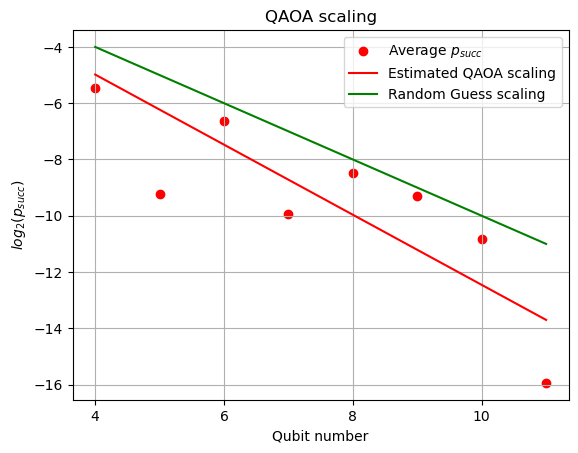

[1.24552157]
[0.08518914]


In [17]:
spread_data3 = {'4': [0.14173828125000001, 0.00404296875, 0.00119140625, 0.00205078125, 0.0275390625, 0.00173828125, 0.0016601562500000004, 0.0013281249999999999, 0.02291015625],
                '5': [0.0022998046875, 0.0003759765625, 0.000390625, 0.00032226562499999996, 0.0048828125],
               '6': [0.08266235351562501, 0.00034667968749999993, 0.00010864257812499999, 0.000369873046875, 0.004222412109375, 0.0001220703125, 0.00037841796875, 0.00010620117187499999, 0.0031579589843750006], 
               '7': [0.0033233642578125, 2.960205078125e-05, 0.00057098388671875, 2.1667480468750002e-05, 0.00109619140625],
               '8': [0.023729934692382812, 8.163452148437499e-06, 9.002685546875e-06, 4.18853759765625e-05, 0.0009940338134765627, 7.705688476562502e-06, 0.00014549255371093748, 6.866455078125e-06, 0.0001265716552734375], 
               '9': [0.013235816955566401, 2.5177001953124997e-06, 2.460479736328125e-06, 0.0004653358459472655, 0.00025756835937500004, 5.168914794921875e-06, 9.84001159667969e-05, 1.697540283203125e-06, 0.00014705657958984374], 
               '10': [0.004641418457031249, 2.5081634521484382e-06, 3.862380981445312e-06, 7.843971252441408e-05, 8.996009826660156e-05, 1.888275146484375e-06, 9.375572204589843e-05, 4.57763671875e-07, 1.2679100036621092e-05],
               '11': [6.043672561645508e-05, 2.0980834960937497e-07, 2.8800964355468754e-06, 1.1086463928222657e-07],
               } 

averages = np.array([np.mean(values) for values in spread_data3.values()])
visualize_experiment(averages)

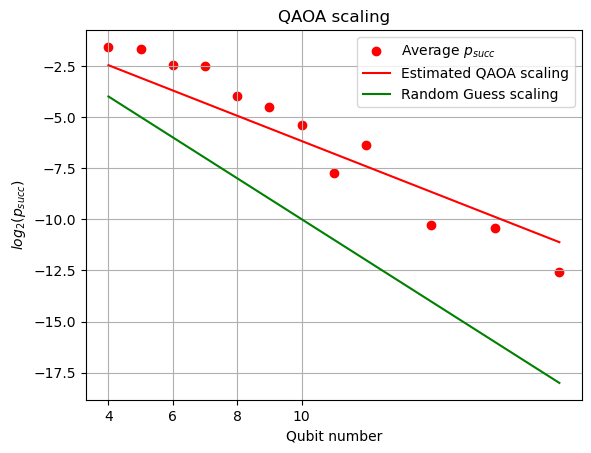

[0.6178105]
[0.03340336]


In [13]:
spread_data1 = {'4': [0.49468749999999984, 0.25875000000000004, 0.03, 0.49093749999999997, 0.495625, 0.33062499999999995, 0.480625, 0.1746875, 0.25999999999999995],
                '5': [0.465625, 0.3165625, 0.45828125000000003, 0.1234375, 0.20531249999999995], 
               '6': [0.282734375, 0.11656249999999999, 0.009609375, 0.22914062500000001, 0.32484375, 0.1525, 0.29976562500000004, 0.094296875, 0.10273437500000002], 
               '7': [0.29484375000000007, 0.13871093750000002, 0.28792968750000003, 0.06980468749999999, 0.08789062500000001],
               '8': [0.09500000000000001, 0.0571484375, 0.00458984375, 0.05734374999999999, 0.12658203125, 0.041718750000000006, 0.11900390624999999, 0.02927734375, 0.0403125], 
               '9': [0.06341796875000001, 0.035117187499999994, 0.0026269531250000004, 0.05901367187500001, 0.08154296874999999, 0.028955078124999995, 0.0754296875, 0.011396484374999998, 0.033720703124999994], 
               '10': [0.030083007812499996, 0.03873046875000001, 0.0011523437500000002, 0.026557617187500004, 0.022670898437499996, 0.010478515624999999, 0.03904296875, 0.0058203125, 0.039277343750000006], 
               '12': [0.005345458984375, 0.0090869140625, 0.0009179687500000001, 0.003291015625], 
               '11': [0.01325439453125, 0.0043115234375, 0.018369140625000002, 0.0036376953125, 0.021540527343749998],
               '14': [0.00118804931640625, 0.00141357421875, 0.00022857666015624993, 0.00036132812500000005], 
               '16': [0.00042015075683593745, 0.002164154052734375, 6.248474121093751e-05, 0.00021507263183593748], 
               '18': [0.00014261245727539064, 0.0004805946350097657, 2.1190643310546877e-05, 1.9283294677734377e-05]} 

averages = np.array([np.mean(values) for values in spread_data1.values()])
visualize_experiment(averages)

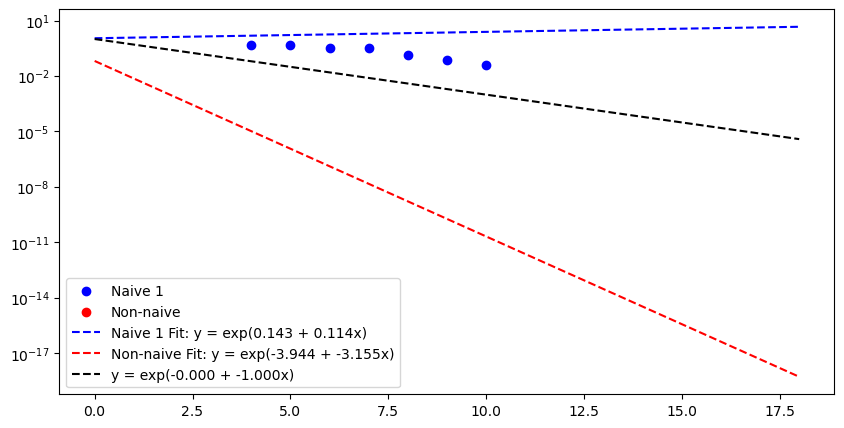

In [10]:
# new data with parameter pre-training:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def exponential_growth(x, alpha):
    return (-alpha*x)

# naive approach (quadratic terms scaling, n qubits)
spread_data1 = {'4': [0.5796875, 0.6112500000000001, 0.3453125, 0.559375, 0.5596874999999999, 0.43281249999999993, 0.6631250000000001, 0.1946875, 0.43218750000000006, 0.468125], 
                '5': [0.5731249999999999, 0.6639062499999999, 0.31968749999999996, 0.5525000000000001, 0.525625, 0.47453125000000007, 0.6534375, 0.13109375, 0.40453124999999995, 0.460625], 
                '6': [0.36539062499999997, 0.47429687499999995, 0.21382812499999998, 0.3154687500000001, 0.356796875, 0.29460937499999995, 0.49015624999999996, 0.13859374999999996, 0.30070312499999996, 0.246015625], 
                '7': [0.395703125, 0.509453125, 0.1770703125, 0.310078125, 0.3243359375, 0.34203125, 0.43875000000000003, 0.10523437499999999, 0.28671875, 0.25976562499999994], 
                '8': [0.13033203124999998, 0.30853515624999994, 0.05482421875000001, 0.11513671875, 0.13292968750000003, 0.10308593749999999, 0.20667968750000001, 0.117109375, 0.13070312499999998, 0.11021484374999999], 
                '9': [0.06792968749999999, 0.18714843750000001, 0.02423828125, 0.04523437500000001, 0.036181640625, 0.053623046875000004, 0.09547851562500001, 0.0948828125, 0.060791015625, 0.04931640625], 
                '10': [0.030239257812499996, 0.1194677734375, 0.013872070312500002, 0.023466796875, 0.0200048828125, 0.012700195312499999, 0.05535156249999999, 0.0716064453125, 0.027734375, 0.028315429687499998], 
                '11': [], '12': [], '14': [], '16': [], '18': []} 

sizes_spread = np.array(list(spread_data1.keys()), dtype=float)
means1 = np.array([np.mean(values) for values in spread_data1.values()])
valid_indices = ~np.isnan(means1)
sizes_spread1 = sizes_spread[valid_indices]
means1 = means1[valid_indices]

# Perform the curve fitting
popt, pcov = curve_fit(exponential_growth, sizes_spread1, means1, p0=[0])
alpha_opt = popt
param_errors = np.sqrt(np.diag(pcov))
y_fit1 = exponential_growth(sizes_spread1, alpha_opt)

# naive-2 2n qubits
spread_data2 = {'4': [0.6116796875, 0.5594726562499999, 0.565703125, 0.5226953125, 0.6351171875], 
                '5': [0.6658984375, 0.5926123046875, 0.5687548828125, 0.5509667968749999, 0.6128320312500001], 
                '6': [0.34485595703125005, 0.323756103515625, 0.30978027343750003, 0.3073974609375, 0.35415405273437495], 
                '7': [0.4039956665039063, 0.35088867187499995, 0.31263519287109376, 0.3319024658203125, 0.35745666503906254], 
                '8': [0.12595390319824218, 0.11264610290527344, 0.09220252990722656, 0.09985931396484375, 0.1271385955810547], 
                '9': [0.05420434951782227, 0.024082279205322264, 0.04926309585571289, 0.02406286239624023, 0.05503414154052734], 
                '10': [0.04495586395263672, 0.027582349777221682, 0.017690339088439942, 0.015263552665710448, 0.019000000953674316], 
                '11': [], '12': [], '14': [], '16': [], '18': []}   

sizes_spread = np.array(list(spread_data2.keys()), dtype=float)
means2 = np.array([np.mean(values) for values in spread_data2.values()])
valid_indices = ~np.isnan(means2)
sizes_spread2 = sizes_spread[valid_indices]
means2 = np.log2(means2[valid_indices])

# Perform the curve fitting
popt, pcov = curve_fit(exponential_growth, sizes_spread2, means2, p0=[0])
alpha_opt = popt
param_errors = np.sqrt(np.diag(pcov))
y_fit2 = exponential_growth(sizes_spread2, alpha_opt)

# non-naive 2n qubits
spread_data3 = {'4': [0.01953125, 0.11064453125000002, 0.06824218750000001, 0.0626171875, 0.10140625, 0.02515625, 0.11505859375000001, 0.07517578124999999, 0.18677734375000002, 0.018750000000000003], 
                '5': [0.0141748046875, 0.08479492187500001, 0.029511718750000006, 0.034287109375, 0.05634765625, 0.009267578125000002, 0.0436376953125, 0.038955078125, 0.12724609375, 0.006254882812499999], 
                '6': [0.005267333984375001, 0.045631103515625, 0.02808837890625, 0.027015380859375, 0.05142944335937499, 0.007681884765625001, 0.03656005859375, 0.0357470703125, 0.090087890625, 0.004228515625], 
                '7': [0.0036013793945312497, 0.03752899169921875, 0.01750244140625, 0.01846343994140625, 0.03764221191406249, 0.0046258544921874995, 0.021489868164062495, 0.022761840820312497, 0.03862762451171875, 0.0016918945312500004], 
                '8': [0.0023521423339843747, 0.021632080078124998, 0.017041397094726567, 0.018323287963867185, 0.03280937194824218, 0.004295120239257813, 0.015390090942382811, 0.019403762817382812, 0.013105010986328127, 0.000985260009765625], 
                '9': [0.0009847450256347658, 0.004508075714111328, 0.013426132202148435, 0.014486351013183593, 0.021313667297363278, 0.0034242248535156254, 0.00807313919067383, 0.010253238677978515, 0.013846359252929685, 0.0006520271301269532], 
                '10': [0.001602764129638672, 0.003888511657714844, 0.009522414207458496, 0.010054812431335448, 0.012785544395446777, 0.00226287841796875, 0.0022235679626464843, 0.004226026535034179, 0.0018048191070556634, 0.0002630043029785156], 
                '11': [], '12': [], '14': [], '16': [], '18': []} 

sizes_spread = np.array(list(spread_data3.keys()), dtype=float)
means3 = np.array([np.mean(values) for values in spread_data3.values()])
valid_indices = ~np.isnan(means3)
sizes_spread3 = sizes_spread[valid_indices]
means3 = np.log2(means3[valid_indices])

# Perform the curve fitting
popt, pcov = curve_fit(exponential_growth, sizes_spread3, means3, p0=[0])
alpha_opt = popt
param_errors = np.sqrt(np.diag(pcov))
y_fit3 = exponential_growth(sizes_spread3, alpha_opt)

means4 = [np.log2(1/(2**x)) for x in sizes_spread3]
log_fit4 = np.polyfit(sizes_spread3, means4, 1)  # Fit a line in log-space

# plot all 3 above:
plt.figure(figsize=(10, 5))
plt.scatter(sizes_spread1, means1, label='Naive 1', color='blue')
#plt.scatter(sizes_spread2, means2, label='Naive 2', color='green')
plt.scatter(sizes_spread3, means3, label='Non-naive', color='red')
extended_sizes = np.linspace(0, 18, 100)

# Extend the fitted lines
extended_fit_values1 = np.exp2(y_fit1[1] + y_fit1[0] * extended_sizes)
#extended_fit_values2 = np.exp2(log_fit2[1] + log_fit2[0] * extended_sizes)
extended_fit_values3 = np.exp2(y_fit3[1] + y_fit3[0] * extended_sizes)
extended_fit_values4 = np.exp2(log_fit4[1] + log_fit4[0] * extended_sizes)

plt.plot(extended_sizes, extended_fit_values1, linestyle='dashed', color='blue', label=f"Naive 1 Fit: y = exp({y_fit1[1]:.3f} + {y_fit1[0]:.3f}x)")
#plt.plot(extended_sizes, extended_fit_values2, linestyle='dashed', color='green', label=f"Naive 2 Fit: y = exp({log_fit2[1]:.3f} + {log_fit2[0]:.3f}x)")
plt.plot(extended_sizes, extended_fit_values3, linestyle='dashed', color='red', label=f"Non-naive Fit: y = exp({y_fit3[1]:.3f} + {y_fit3[0]:.3f}x)")

plt.plot(extended_sizes, extended_fit_values4, linestyle='dashed', color='black', label=f"y = exp({log_fit4[1]:.3f} + {log_fit4[0]:.3f}x)")

plt.yscale("log")
plt.legend()
plt.show()

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

from scipy.optimize import curve_fit


def plot_log2_best_fit(experiment_name, *datasets, max_size=None, min_size=0, scatter=True, weight=False, error_bars=False, brute_force=True):
    if max_size is None:
        max_size = [max(int(k) for k in d[0].keys()) for d in datasets]
        
    plt.figure(figsize=(10, 6))
    
    def exponential_growth(x, alpha):
        return -alpha * x
    
    for idx, data in enumerate(datasets):
        # Convert keys to integers (x values)
        x_values = np.array([int(k) for k in data[0].keys()])
        
        # Compute log2 of values
        log2_values = {k: np.log2(v) for k, v in data[0].items()}
        
        # Compute average log2 values for each x and their uncertainties
        avg_log2_values = np.array([np.mean(v) for k, v in log2_values.items()])
        uncertainties = np.array([np.std(np.log2(v)) / np.sqrt(len(v)) for k, v in data[0].items()])
        
        # Perform curve fitting
        weights = np.ones_like(avg_log2_values)
        if weight:
            weights[:5] = 1.75  # Reduce weight for the first three values
            weights[-3:] = 0.25  # Increase weight for the last three values
        popt, pcov = curve_fit(exponential_growth, x_values, avg_log2_values, p0=[0], sigma=weights)
        alpha_opt = popt[0]
        
        # Generate the fitted curve using the optimized parameters
        x_fit = np.linspace(min_size, max(max_size), 100)
        y_fit = exponential_growth(x_fit, alpha_opt)
        
        # Plot data
        colors = ['lightblue', 'lightgreen', 'lightcoral', 'lightsalmon', 'lightpink']
        mean_colors = ['blue', 'green', 'red', 'salmon', 'pink']
        for idx2, (k, v) in enumerate(log2_values.items()):
            if int(k) >= min_size:
                if idx2 == 0:
                    plt.scatter(int(k), avg_log2_values[idx2], color=mean_colors[idx % len(mean_colors)], edgecolor='black', label=f'{data[1]}: average $p_{{succ}}$')
                    if error_bars: plt.errorbar(int(k), np.mean(v), yerr=np.std(v), fmt='o', ecolor='darkred', color='none', label=f'{data[1]}: standard deviation')
                if scatter: plt.scatter([int(k)] * len(v), v, alpha=0.5, color=colors[idx % len(colors)])
                if error_bars: plt.errorbar(int(k), np.mean(v), yerr=np.std(v), fmt='o', ecolor='darkred', color='none')
                plt.scatter(int(k), avg_log2_values[idx2], color=mean_colors[idx % len(mean_colors)], edgecolor='black')
        plt.plot(x_fit, y_fit, '--', color=mean_colors[idx % len(mean_colors)], label=f'{data[1]}: Best fit (y=-{alpha_opt:.4f}x)')
    
    # Generate the y values for -1*x (alpha = 1)
    x_fit_global = np.linspace(min_size, max(max(int(k) for k in d[0].keys()) for d in datasets), 100)
    y_minus_x = exponential_growth(x_fit_global, 1)
    if brute_force: plt.plot(x_fit_global, y_minus_x, 'r-.', label='Brute force (y = -1x)')
    
    plt.xlabel('Graph size')
    plt.ylabel('$log_2(p_{succ})$')
    plt.title('QAOA Scaling')
    plt.legend()
    plt.grid()
    
    plt.savefig(f"Scaling-figures/{experiment_name}.pdf")
    
    plt.show()

data = {'4': [0.5796875, 0.6112500000000001, 0.3453125, 0.559375, 0.5596874999999999, 0.43281249999999993, 0.6631250000000001, 0.1946875, 0.43218750000000006, 0.468125], 
                '5': [0.5731249999999999, 0.6639062499999999, 0.31968749999999996, 0.5525000000000001, 0.525625, 0.47453125000000007, 0.6534375, 0.13109375, 0.40453124999999995, 0.460625], 
                '6': [0.36539062499999997, 0.47429687499999995, 0.21382812499999998, 0.3154687500000001, 0.356796875, 0.29460937499999995, 0.49015624999999996, 0.13859374999999996, 0.30070312499999996, 0.246015625], 
                '7': [0.395703125, 0.509453125, 0.1770703125, 0.310078125, 0.3243359375, 0.34203125, 0.43875000000000003, 0.10523437499999999, 0.28671875, 0.25976562499999994], 
                '8': [0.13033203124999998, 0.30853515624999994, 0.05482421875000001, 0.11513671875, 0.13292968750000003, 0.10308593749999999, 0.20667968750000001, 0.117109375, 0.13070312499999998, 0.11021484374999999], 
                '9': [0.06792968749999999, 0.18714843750000001, 0.02423828125, 0.04523437500000001, 0.036181640625, 0.053623046875000004, 0.09547851562500001, 0.0948828125, 0.060791015625, 0.04931640625], 
                '10': [0.030239257812499996, 0.1194677734375, 0.013872070312500002, 0.023466796875, 0.0200048828125, 0.012700195312499999, 0.05535156249999999, 0.0716064453125, 0.027734375, 0.028315429687499998], 
}

data2 = {'4': [0.6116796875, 0.5594726562499999, 0.565703125, 0.5226953125, 0.6351171875], 
                '5': [0.6658984375, 0.5926123046875, 0.5687548828125, 0.5509667968749999, 0.6128320312500001], 
                '6': [0.34485595703125005, 0.323756103515625, 0.30978027343750003, 0.3073974609375, 0.35415405273437495], 
                '7': [0.4039956665039063, 0.35088867187499995, 0.31263519287109376, 0.3319024658203125, 0.35745666503906254], 
                '8': [0.12595390319824218, 0.11264610290527344, 0.09220252990722656, 0.09985931396484375, 0.1271385955810547], 
                '9': [0.05420434951782227, 0.024082279205322264, 0.04926309585571289, 0.02406286239624023, 0.05503414154052734], 
                '10': [0.04495586395263672, 0.027582349777221682, 0.017690339088439942, 0.015263552665710448, 0.019000000953674316], 
}

data3 = {'4': [0.01953125, 0.11064453125000002, 0.06824218750000001, 0.0626171875, 0.10140625, 0.02515625, 0.11505859375000001, 0.07517578124999999, 0.18677734375000002, 0.018750000000000003], 
                '5': [0.0141748046875, 0.08479492187500001, 0.029511718750000006, 0.034287109375, 0.05634765625, 0.009267578125000002, 0.0436376953125, 0.038955078125, 0.12724609375, 0.006254882812499999], 
                '6': [0.005267333984375001, 0.045631103515625, 0.02808837890625, 0.027015380859375, 0.05142944335937499, 0.007681884765625001, 0.03656005859375, 0.0357470703125, 0.090087890625, 0.004228515625], 
                '7': [0.0036013793945312497, 0.03752899169921875, 0.01750244140625, 0.01846343994140625, 0.03764221191406249, 0.0046258544921874995, 0.021489868164062495, 0.022761840820312497, 0.03862762451171875, 0.0016918945312500004], 
                '8': [0.0023521423339843747, 0.021632080078124998, 0.017041397094726567, 0.018323287963867185, 0.03280937194824218, 0.004295120239257813, 0.015390090942382811, 0.019403762817382812, 0.013105010986328127, 0.000985260009765625], 
                '9': [0.0009847450256347658, 0.004508075714111328, 0.013426132202148435, 0.014486351013183593, 0.021313667297363278, 0.0034242248535156254, 0.00807313919067383, 0.010253238677978515, 0.013846359252929685, 0.0006520271301269532], 
                '10': [0.001602764129638672, 0.003888511657714844, 0.009522414207458496, 0.010054812431335448, 0.012785544395446777, 0.00226287841796875, 0.0022235679626464843, 0.004226026535034179, 0.0018048191070556634, 0.0002630043029785156], 
                } 

# plot_log2_best_fit(data)
# # plot_log2_best_fit(data2)
# plot_log2_best_fit(data3)
# plot_log2_best_fit(data, data3)


In [2]:
data1_noisy = {'4': [0.4846875, 0.433125, 0.5237499999999999, 0.4815624999999999, 0.6128125000000002, 0.4421875, 0.5696875, 0.5106249999999999, 0.3896875, 0.3565625], 
               '5': [0.48625000000000007, 0.40953125, 0.5107812500000001, 0.45078125, 0.6385937500000001, 0.37921875, 0.551875, 0.52921875, 0.34078125000000004, 0.44140625], 
               '6': [0.27765625, 0.21570312499999997, 0.36726562499999993, 0.23484375000000007, 0.428203125, 0.27171874999999995, 0.39343750000000005, 0.36734374999999997, 0.21726562500000002, 0.19734375], 
               '7': [0.29265624999999995, 0.1999609375, 0.35828125, 0.22914062499999996, 0.44925781249999996, 0.21066406250000003, 0.31820312500000003, 0.357421875, 0.2035546875, 0.25796874999999997], 
               '8': [0.105859375, 0.0655078125, 0.1104296875, 0.07826171874999999, 0.22154296874999999, 0.12363281250000002, 0.1440234375, 0.13994140624999998, 0.09234374999999999, 0.03533203125], 
               '9': [0.07491210937500001, 0.042880859375000004, 0.024677734375, 0.029423828125000002, 0.12643554687500003, 0.050556640624999996, 0.06587890625, 0.042939453125000006, 0.06682617187499999, 0.0349609375], 
               '10': [0.0385693359375, 0.022695312500000002, 0.016840820312500004, 0.01169921875, 0.07654785156250002, 0.029658203124999998, 0.030200195312499994, 0.028173828124999994, 0.032597656249999996, 0.0224169921875], 
# data1_noisy = {
               '11': [0.02837158203125, 0.021733398437500002, 0.04131591796875, 0.004387207031250001, 0.00595458984375, 0.018681640625000002, 0.024609374999999996, 0.061154785156250016, 0.021269531249999998, 0.01918701171875], 
               '12': [0.008878173828125, 0.0049365234375, 0.0117138671875, 0.00101318359375, 0.001593017578125, 0.006010742187499999, 0.004548339843750001, 0.01315673828125, 0.0024060058593749997, 0.007725830078125001], 
               '14': [0.003916015625, 0.000302734375, 0.0042657470703125, 0.00026092529296875, 0.0003521728515624999, 0.00039520263671875, 0.00073699951171875, 0.0028292846679687502, 0.00074310302734375, 0.0014733886718749998], 
               '16': [0.00275146484375, 0.000153350830078125, 0.0007326507568359375, 0.00012908935546874999, 0.00017150878906249998, 0.000139617919921875, 0.00012626647949218748, 0.00047126770019531247, 0.0005855560302734376, 0.0004241180419921876], 
               '18': [0.0015536117553710937, 7.9803466796875e-05, 0.0005490684509277344, 1.2836456298828124e-05, 1.7013549804687503e-05, 3.091812133789063e-05, 0.00013904571533203126, 0.0008670234680175781, 7.690429687500001e-05, 0.00015644073486328127]} 

data2_noisy = {'4': [0.008300781250000002, 0.05748046875, 0.03404296875, 0.1082421875, 0.06812499999999999, 0.028378906249999995, 0.0140234375, 0.3273828125, 0.0496484375, 0.04291015625], 
               '5': [0.00185546875, 0.0283447265625, 0.0131982421875, 0.062055664062499995, 0.031503906250000005, 0.01109375, 0.003940429687499999, 0.23872558593749998, 0.019091796875000004, 0.021552734375], 
               '6': [0.0022778320312500005, 0.0181005859375, 0.014921875000000001, 0.05822509765625, 0.030021972656249996, 0.00810791015625, 0.004921875, 0.19018798828125, 0.018450927734375, 0.016278076171874996], 
               '7': [0.0003982543945312501, 0.0109136962890625, 0.01000640869140625, 0.045704040527343746, 0.019241943359375003, 0.00583099365234375, 0.0010308837890624998, 0.1676177978515625, 0.008216552734374999, 0.0114801025390625], 
               '8': [0.0006258392333984375, 0.005400390624999999, 0.009716339111328126, 0.04623687744140625, 0.02040016174316406, 0.004733505249023438, 0.0015427398681640623, 0.09102684020996094, 0.0049041748046875, 0.008803482055664062], 
               '9': [0.00080047607421875, 0.0037011909484863286, 0.008107032775878906, 0.03967731475830078, 0.016546916961669923, 0.002963409423828125, 0.0024885940551757804, 0.05118173599243164, 0.00352123260498047, 0.005555706024169922], 
               '10': [0.00032038211822509765, 0.0023979043960571287, 0.004712948799133301, 0.030094037055969237, 0.010172605514526365, 0.0015426969528198244, 0.0014080190658569336, 0.015043816566467286, 0.002415204048156738, 0.0028707456588745114], 
               '11': [0.0022945868968963622]
               } 

plot_log2_best_fit(data1_noisy)
plot_log2_best_fit(data2_noisy)
plot_log2_best_fit(data1_noisy, data2_noisy)

NameError: name 'plot_log2_best_fit' is not defined

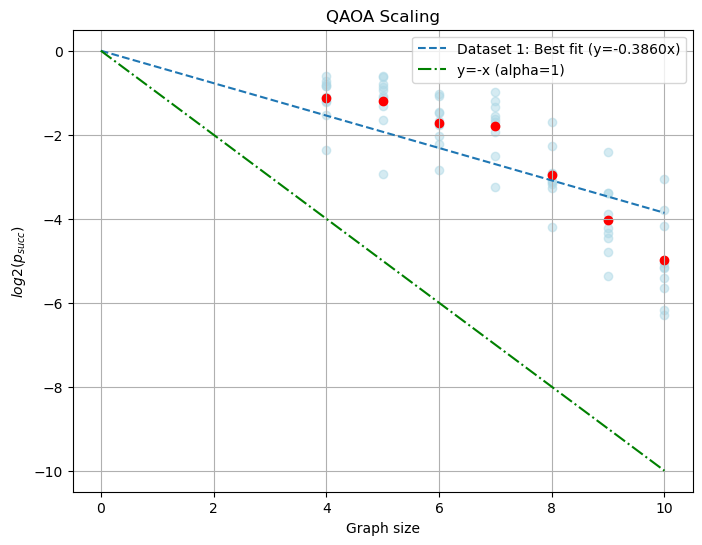

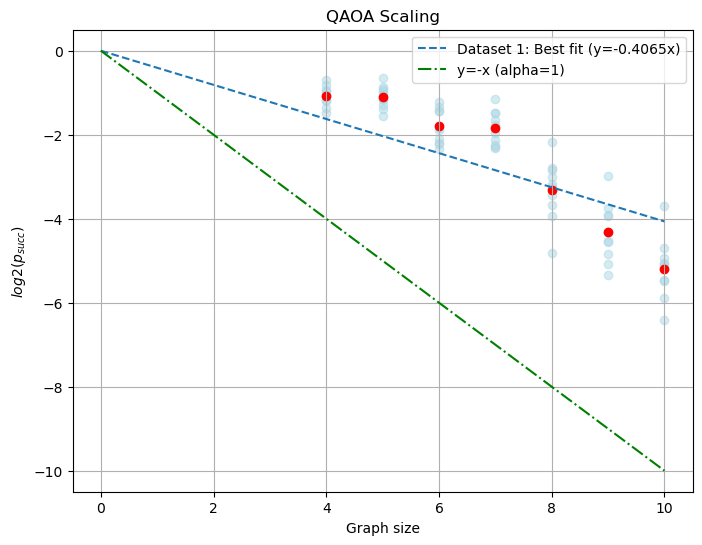

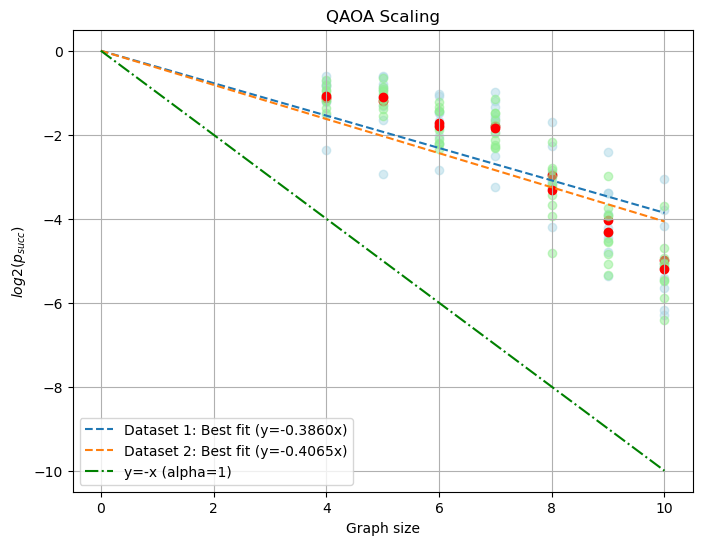

In [8]:
data_naive_clean = {'4': [0.5796875, 0.6112500000000001, 0.3453125, 0.559375, 0.5596874999999999, 0.43281249999999993, 0.6631250000000001, 0.1946875, 0.43218750000000006, 0.468125], 
                '5': [0.5731249999999999, 0.6639062499999999, 0.31968749999999996, 0.5525000000000001, 0.525625, 0.47453125000000007, 0.6534375, 0.13109375, 0.40453124999999995, 0.460625], 
                '6': [0.36539062499999997, 0.47429687499999995, 0.21382812499999998, 0.3154687500000001, 0.356796875, 0.29460937499999995, 0.49015624999999996, 0.13859374999999996, 0.30070312499999996, 0.246015625], 
                '7': [0.395703125, 0.509453125, 0.1770703125, 0.310078125, 0.3243359375, 0.34203125, 0.43875000000000003, 0.10523437499999999, 0.28671875, 0.25976562499999994], 
                '8': [0.13033203124999998, 0.30853515624999994, 0.05482421875000001, 0.11513671875, 0.13292968750000003, 0.10308593749999999, 0.20667968750000001, 0.117109375, 0.13070312499999998, 0.11021484374999999], 
                '9': [0.06792968749999999, 0.18714843750000001, 0.02423828125, 0.04523437500000001, 0.036181640625, 0.053623046875000004, 0.09547851562500001, 0.0948828125, 0.060791015625, 0.04931640625], 
                '10': [0.030239257812499996, 0.1194677734375, 0.013872070312500002, 0.023466796875, 0.0200048828125, 0.012700195312499999, 0.05535156249999999, 0.0716064453125, 0.027734375, 0.028315429687499998], 
}

data_naive_noisy = {'4': [0.4846875, 0.433125, 0.5237499999999999, 0.4815624999999999, 0.6128125000000002, 0.4421875, 0.5696875, 0.5106249999999999, 0.3896875, 0.3565625], 
               '5': [0.48625000000000007, 0.40953125, 0.5107812500000001, 0.45078125, 0.6385937500000001, 0.37921875, 0.551875, 0.52921875, 0.34078125000000004, 0.44140625], 
               '6': [0.27765625, 0.21570312499999997, 0.36726562499999993, 0.23484375000000007, 0.428203125, 0.27171874999999995, 0.39343750000000005, 0.36734374999999997, 0.21726562500000002, 0.19734375], 
               '7': [0.29265624999999995, 0.1999609375, 0.35828125, 0.22914062499999996, 0.44925781249999996, 0.21066406250000003, 0.31820312500000003, 0.357421875, 0.2035546875, 0.25796874999999997], 
               '8': [0.105859375, 0.0655078125, 0.1104296875, 0.07826171874999999, 0.22154296874999999, 0.12363281250000002, 0.1440234375, 0.13994140624999998, 0.09234374999999999, 0.03533203125], 
               '9': [0.07491210937500001, 0.042880859375000004, 0.024677734375, 0.029423828125000002, 0.12643554687500003, 0.050556640624999996, 0.06587890625, 0.042939453125000006, 0.06682617187499999, 0.0349609375], 
               '10': [0.0385693359375, 0.022695312500000002, 0.016840820312500004, 0.01169921875, 0.07654785156250002, 0.029658203124999998, 0.030200195312499994, 0.028173828124999994, 0.032597656249999996, 0.0224169921875], 
}

plot_log2_best_fit(data_naive_clean)
plot_log2_best_fit(data_naive_noisy)
plot_log2_best_fit(data_naive_clean, data_naive_noisy)

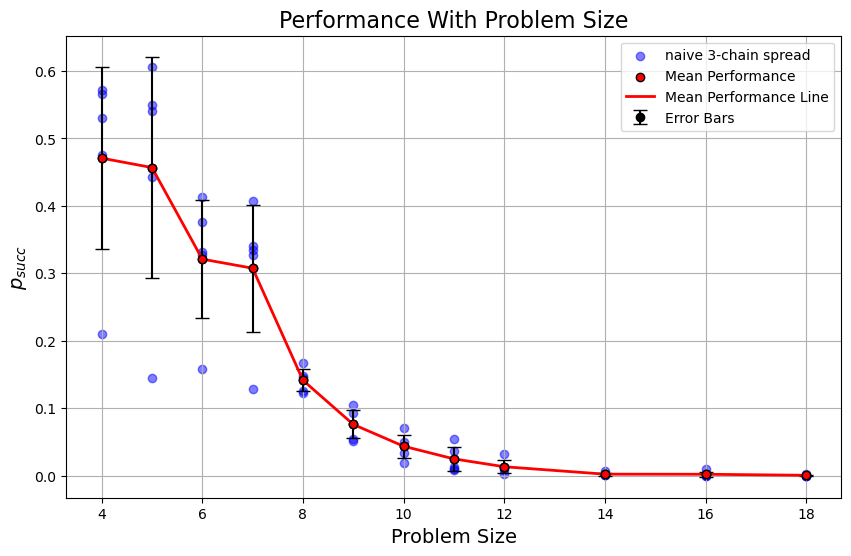

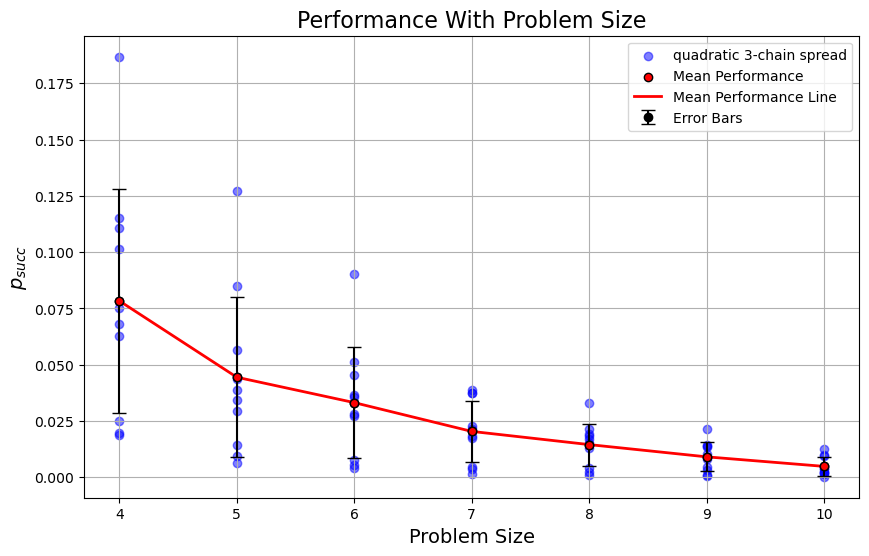

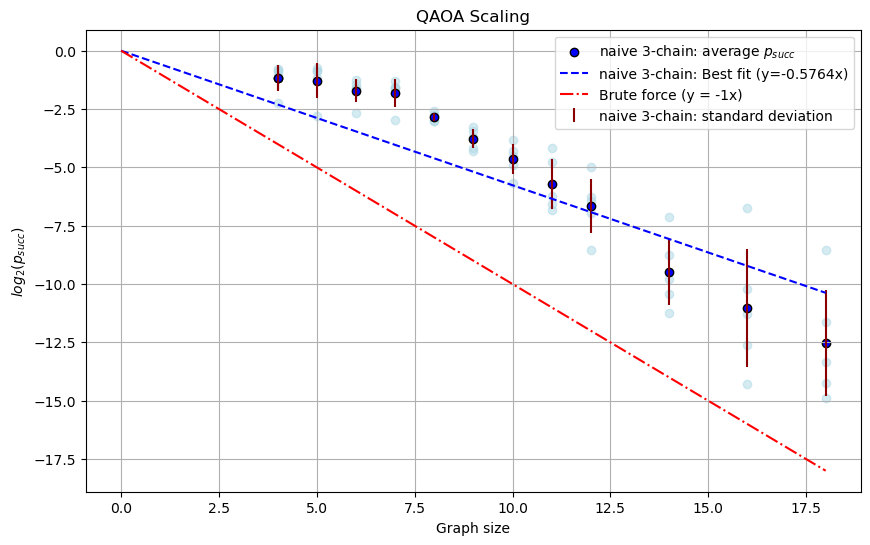

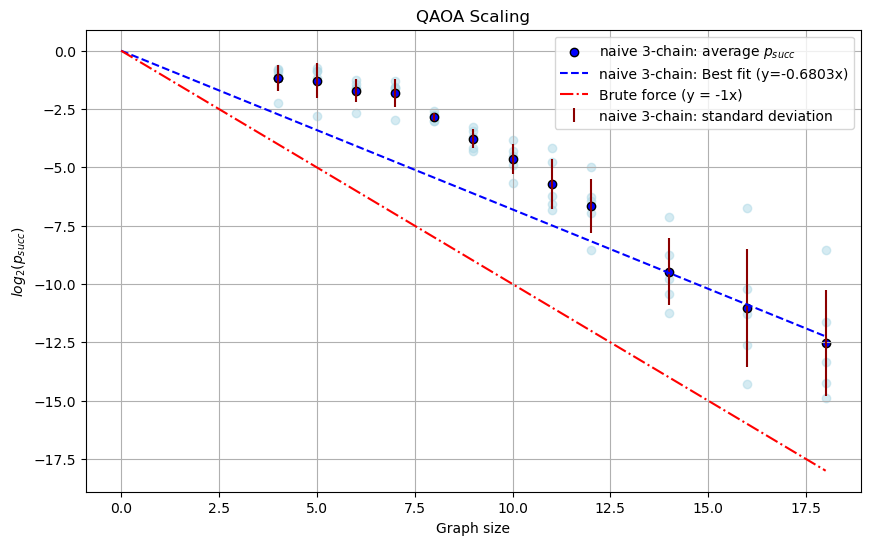

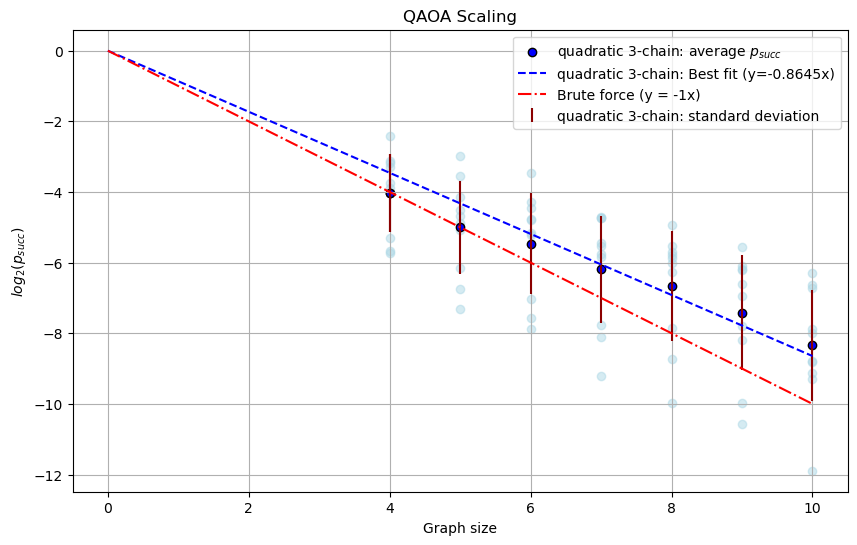

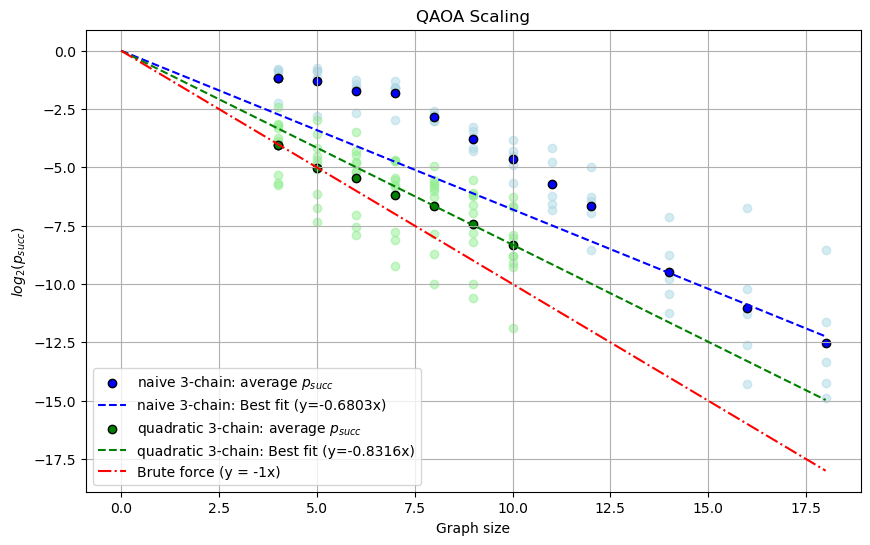

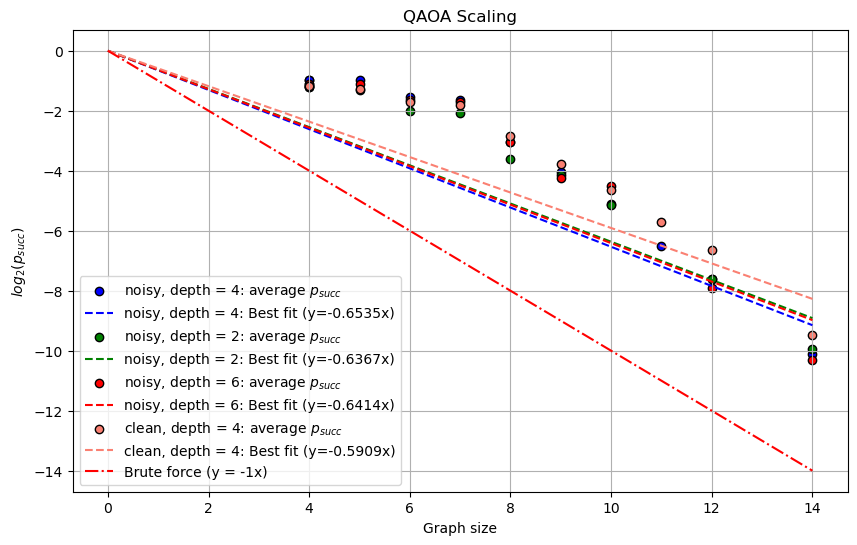

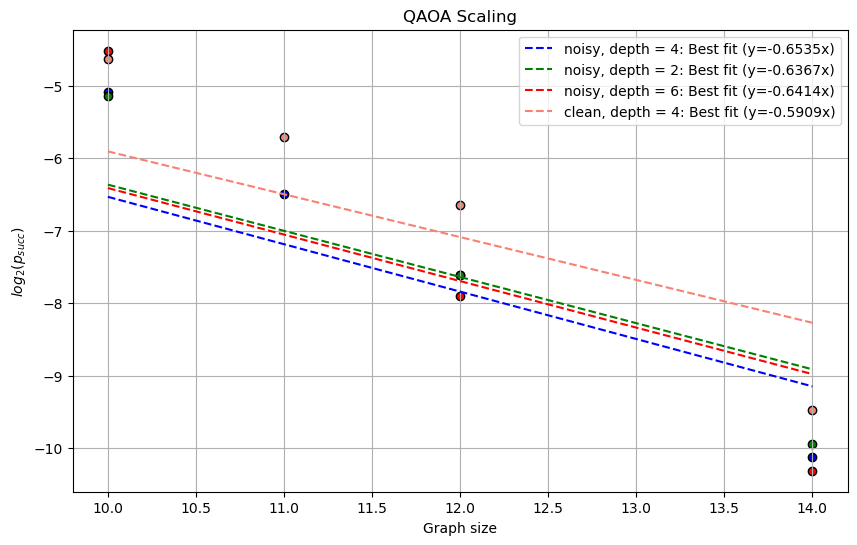

In [29]:
data_naive_clean = {'4': [0.20968749999999997, 0.53, 0.5725, 0.4759375, 0.56625], 
                    '5': [0.14562499999999995, 0.54078125, 0.5495312499999999, 0.44234375000000004, 0.60625], 
                    '6': [0.15812500000000002, 0.37562500000000004, 0.41296874999999994, 0.3315625, 0.32742187500000003], 
                    '7': [0.12789062499999998, 0.32777343750000004, 0.34031249999999996, 0.33527343750000005, 0.40703125], 
                    '8': [0.12488281250000002, 0.12259765625, 0.14849609375, 0.14505859375, 0.1666796875], 
                    '9': [0.09286132812499999, 0.05145507812500001, 0.05478515625000001, 0.10472656249999998, 0.076572265625], 
                    '10': [0.07137207031249998, 0.01947265625, 0.0334326171875, 0.05011718749999999, 0.044384765625], 
                    '11': [0.05489746093750001, 0.00876220703125, 0.01041748046875, 0.03719482421874999, 0.013530273437499999], 
                    '12': [0.031690673828125, 0.0026989746093749995, 0.011365966796874998, 0.012834472656249998, 0.008024902343750001], 
                    '14': [0.007056884765625, 0.00072296142578125, 0.00040771484375, 0.00234710693359375, 0.0011294555664062502], 
                    '16': [0.009491195678710937, 0.00016044616699218748, 5.0811767578124994e-05, 0.000835418701171875, 0.000400238037109375], 
                    '18': [0.002686080932617187, 3.2939910888671874e-05, 5.092620849609375e-05, 0.00032093048095703123, 9.746551513671875e-05]
                    }

data_naive_noisy2 = {'4': [0.6315625, 0.5253125, 0.5728125000000001, 0.4875000000000001, 0.3540625], 
                     '5': [0.61484375, 0.56953125, 0.5873437499999999, 0.47765625, 0.344375], 
                     '6': [0.40296875, 0.36078125000000005, 0.42625, 0.3444531250000001, 0.22585937499999997], 
                     '7': [0.3645312500000001, 0.35714843749999997, 0.37132812499999995, 0.32843750000000005, 0.20347656250000004], 
                     '8': [0.12388671875000001, 0.11232421875000001, 0.1380859375, 0.13390625, 0.09806640625000002], 
                     '9': [0.04108398437500001, 0.12516601562500002, 0.080029296875, 0.03494140625000001, 0.056650390625000005], 
                     '10': [0.017128906250000003, 0.08176757812499999, 0.042744140624999996, 0.015444335937500001, 0.023120117187499997], 
                     '11': [0.00840087890625, 0.033776855468750006, 0.02017578125, 0.0019287109375, 0.01506591796875], 
                     '12': [0.0037548828125, 0.008543701171875001, 0.007124023437499999, 0.00223876953125, 0.006699218750000001], 
                    '14': [0.0010809326171875, 0.0017877197265625, 0.00040222167968750005, 0.00066741943359375, 0.0011077880859375], 
                    #'16': [], '18': []
                     }

data_quadratic_clean = {'4': [0.01953125, 0.11064453125000002, 0.06824218750000001, 0.0626171875, 0.10140625, 0.02515625, 0.11505859375000001, 0.07517578124999999, 0.18677734375000002, 0.018750000000000003], 
                '5': [0.0141748046875, 0.08479492187500001, 0.029511718750000006, 0.034287109375, 0.05634765625, 0.009267578125000002, 0.0436376953125, 0.038955078125, 0.12724609375, 0.006254882812499999], 
                '6': [0.005267333984375001, 0.045631103515625, 0.02808837890625, 0.027015380859375, 0.05142944335937499, 0.007681884765625001, 0.03656005859375, 0.0357470703125, 0.090087890625, 0.004228515625], 
                '7': [0.0036013793945312497, 0.03752899169921875, 0.01750244140625, 0.01846343994140625, 0.03764221191406249, 0.0046258544921874995, 0.021489868164062495, 0.022761840820312497, 0.03862762451171875, 0.0016918945312500004], 
                '8': [0.0023521423339843747, 0.021632080078124998, 0.017041397094726567, 0.018323287963867185, 0.03280937194824218, 0.004295120239257813, 0.015390090942382811, 0.019403762817382812, 0.013105010986328127, 0.000985260009765625], 
                '9': [0.0009847450256347658, 0.004508075714111328, 0.013426132202148435, 0.014486351013183593, 0.021313667297363278, 0.0034242248535156254, 0.00807313919067383, 0.010253238677978515, 0.013846359252929685, 0.0006520271301269532], 
                '10': [0.001602764129638672, 0.003888511657714844, 0.009522414207458496, 0.010054812431335448, 0.012785544395446777, 0.00226287841796875, 0.0022235679626464843, 0.004226026535034179, 0.0018048191070556634, 0.0002630043029785156], 
                } 

data_quadratic_noisy = {
    '4': [0.03046875, 0.01279296875, 0.34705078125, 0.05199218750000001, 0.0458984375, 0.0294921875], 
     '5': [0.011298828125, 0.003974609375, 0.24794433593750004, 0.0194921875, 0.022841796875, 0.0113037109375], 
     '6': [0.008671875, 0.004969482421875001, 0.19659057617187498, 0.019110107421875, 0.01716552734375, 0.00867431640625], 
     '7': [0.00587005615234375, 0.0009466552734375, 0.17223052978515627, 0.00807220458984375, 0.011872253417968751, 0.00580230712890625]
}

data_naive_noisy_low_p = {'4': [0.4984375, 0.5565624999999998, 0.5128125000000001, 0.3728125, 0.27468750000000003], 
                          '5': [0.46703125000000006, 0.57875, 0.5360937499999999, 0.36046875, 0.20828125000000003], 
                          '6': [0.27429687499999994, 0.3330468749999999, 0.28359375, 0.19289062499999998, 0.18351562500000002], 
                          '7': [0.23765624999999999, 0.346796875, 0.29652343750000004, 0.18152343750000002, 0.1636328125], 
                          '8': [0.08582031250000001, 0.10646484375000001, 0.085, 0.061250000000000006, 0.07775390625], 
                          '9': [0.04771484375, 0.09583984374999999, 0.043896484375, 0.041455078124999996, 0.070830078125], 
                          '10': [0.028017578124999998, 0.0499755859375, 0.022568359375, 0.020390625000000002, 0.0279052734375], 
                          '12': [0.003935546875, 0.007119140625000001, 0.005380859375000001, 0.0041357421874999994, 0.00547119140625], 
                          '14': [0.0011004638671874999, 0.0018740844726562503, 0.0005364990234374998, 0.00053863525390625, 0.0017852783203125]}

data_naive_noisy_high_p = {'4': [0.465625, 0.4828125, 0.48, 0.5196875000000001, 0.396875], 
                           '5': [0.53015625, 0.5215624999999999, 0.43468750000000006, 0.5148437499999999, 0.3571875], 
                           '6': [0.30148437499999997, 0.315, 0.343515625, 0.359609375, 0.28320312500000006], 
                           '7': [0.335234375, 0.303359375, 0.266796875, 0.341328125, 0.2753515625], 
                           '8': [0.09197265624999999, 0.07802734375, 0.13529296875000002, 0.13425781250000002, 0.20068359375], 
                           '9': [0.03267578125, 0.027138671875, 0.08697265624999999, 0.037138671875, 0.141123046875], 
                           '10': [0.035473632812499996, 0.036293945312500006, 0.0493310546875, 0.023642578125, 0.1046142578125], 
                           '12': [0.0033532714843750007, 0.00279296875, 0.008353271484374999, 0.0006567382812500001, 0.02465087890625], 
                           '14': [0.000916748046875, 0.00047332763671875, 0.00168487548828125, 0.00010253906249999998, 0.004017333984375]}

data_naive_high_noise_high_p = {
    '4': [0.38749999999999996, 0.5271874999999999, 0.49000000000000005, 0.4937500000000001],
    '5': [0.35281250000000003, 0.5093749999999999, 0.44343749999999993, 0.5229687499999999],
    '6': [0.275390625, 0.35500000000000004, 0.3349218749999999, 0.315078125],
    '7': [0.28015625, 0.340234375, 0.26871093749999997, 0.30445312499999994],
    '8': [0.1994140625, 0.13384765625, 0.1390234375, 0.0796484375],
    '9': [0.1416796875, 0.036230468749999994, 0.08663085937500001, 0.026630859375],
    '10': [0.10412109374999998, 0.023066406249999998, 0.049433593750000004, 0.03588378906249999],
    '12': [0.024354248046875, 0.0006591796875, 0.00812744140625, 0.0027380371093750004],
    '14': [0.004014892578125, 0.00010253906250000001, 0.0017041015624999999]
}

# want:
# 1. ideal naive vs ideal quadratic (shows comparison of performance)
# 2. ideal naive vs noisy naive (shows effect of noise)
# 3. ideal quadratic vs noisy quadratic (shows effect of noise)
# 4. noisy naive vs noisy quadratic (compares performance under noise)

def plot_data(data, data_name):
    # plot the data_naive_clean:
    fig, ax = plt.subplots(figsize=(10, 6))

    # Define colors
    scatter_color = 'blue'
    mean_color = 'red'
    error_color = 'black'

    # Plot the data points
    for k, v in data.items():
        ax.scatter([int(k)] * len(v), v, color=scatter_color, alpha=0.5, label=f'{data_name} spread' if k == '4' else "")

    # Plot the means with error bars
    for k, v in data.items():
        mean = np.mean(v)
        std = np.std(v)
        ax.scatter(int(k), mean, color=mean_color, edgecolor='black', zorder=5, label='Mean Performance' if k == '4' else "")
        ax.errorbar(int(k), mean, yerr=std, fmt='o', color=error_color, capsize=5, label='Error Bars' if k == '4' else "")

    # Plot line through means
    ax.plot([int(k) for k in data.keys()], [np.mean(v) for v in data.values()], color=mean_color, linestyle='-', linewidth=2, label='Mean Performance Line')

    # Set labels and title
    ax.set_xlabel('Problem Size', fontsize=14)
    ax.set_ylabel('$p_{succ}$', fontsize=14)
    ax.set_title('Performance With Problem Size', fontsize=16)

    # Add legend
    ax.legend()

    # Add grid
    ax.grid(True)
    
    plt.savefig(f'Scaling-figures/{data_name}_non-log.pdf')

    # Show plot
    plt.show()

plot_data(data_naive_clean, "naive 3-chain") # a1
plot_data(data_quadratic_clean, "quadratic 3-chain") # b1

plot_log2_best_fit("naive 3-chain clean", [data_naive_clean, "naive 3-chain"], weight=False, error_bars=True) #a2
plot_log2_best_fit("navie 3-chain weighted clean", [data_naive_clean, "naive 3-chain"], weight=True, error_bars=True) #a3

plot_log2_best_fit("quadratic 3-chain clean", [data_quadratic_clean, "quadratic 3-chain"], error_bars=True) #b2
plot_log2_best_fit("navie vs quadratic clean weighted", [data_naive_clean, "naive 3-chain"], [data_quadratic_clean, "quadratic 3-chain"], weight=True) #c

data_naive_clean_subset = {'4': [0.20968749999999997, 0.53, 0.5725, 0.4759375, 0.56625], 
                    '5': [0.14562499999999995, 0.54078125, 0.5495312499999999, 0.44234375000000004, 0.60625], 
                    '6': [0.15812500000000002, 0.37562500000000004, 0.41296874999999994, 0.3315625, 0.32742187500000003], 
                    '7': [0.12789062499999998, 0.32777343750000004, 0.34031249999999996, 0.33527343750000005, 0.40703125], 
                    '8': [0.12488281250000002, 0.12259765625, 0.14849609375, 0.14505859375, 0.1666796875], 
                    '9': [0.09286132812499999, 0.05145507812500001, 0.05478515625000001, 0.10472656249999998, 0.076572265625], 
                    '10': [0.07137207031249998, 0.01947265625, 0.0334326171875, 0.05011718749999999, 0.044384765625], 
                    '11': [0.05489746093750001, 0.00876220703125, 0.01041748046875, 0.03719482421874999, 0.013530273437499999], 
                    '12': [0.031690673828125, 0.0026989746093749995, 0.011365966796874998, 0.012834472656249998, 0.008024902343750001], 
                    '14': [0.007056884765625, 0.00072296142578125, 0.00040771484375, 0.00234710693359375, 0.0011294555664062502], 
}

def filter_last_keys(data_dict):
    keys_to_keep = ['10', '12', '14']
    return {k: v for k, v in data_dict.items() if k in keys_to_keep}

data_last = filter_last_keys(data)
data2_last = filter_last_keys(data2)
data3_last = filter_last_keys(data3)
data_naive_clean_last = filter_last_keys(data_naive_clean)
data_naive_clean_subset_last = filter_last_keys(data_naive_clean_subset)
data_naive_high_noise_high_p_last = filter_last_keys(data_naive_high_noise_high_p)
data_naive_noisy2_last = filter_last_keys(data_naive_noisy2)
data_naive_noisy_high_p_last = filter_last_keys(data_naive_noisy_high_p)
data_naive_noisy_low_p_last = filter_last_keys(data_naive_noisy_low_p)
data_quadratic_clean_last = filter_last_keys(data_quadratic_clean)
data_quadratic_noisy_last = filter_last_keys(data_quadratic_noisy)

plot_log2_best_fit("noisy runs", [data_naive_noisy2, "noisy, depth = 4"], [data_naive_noisy_low_p, "noisy, depth = 2"], [data_naive_noisy_high_p, "noisy, depth = 6"], [data_naive_clean_subset, "clean, depth = 4"], scatter=False, weight=True)
plot_log2_best_fit("noisy zoomed", [data_naive_noisy2, "noisy, depth = 4"], [data_naive_noisy_low_p, "noisy, depth = 2"], [data_naive_noisy_high_p, "noisy, depth = 6"], [data_naive_clean_subset, "clean, depth = 4"], min_size=10, scatter=False, brute_force=False, weight=True)

# plot_log2_best_fit([data_naive_clean, "naive ideal"], [data_naive_noisy2, "naive noisy"])
# plot_log2_best_fit([data_naive_noisy2, "naive noisy"], [data_quadratic_clean, "quadratic ideal"])
# plot_log2_best_fit([data_quadratic_noisy, "quadratic noisy"])
# plot_log2_best_fit([data_quadratic_noisy, "quadratic noisy"], [data_quadratic_clean, "quadratic ideal"])

